# 02 Prétraitements : test de la normalisation par image

Objectif : vérifier que la chaîne de prétraitement homogénéise les images sans abîmer le contraste racine / sol.

- Chaîne : recadrage du 120 DPI, correction du fond (validés, notebook 01), **normalisation par image** (testée ici).
- Entrée du modèle : 3 canaux.
- Cadre du notebook 01 : fonds estimés sur le train, essais sur le val, jamais le test.

**L'essentiel** : la normalisation par centiles (gain plafonné à ×3) supprime les dominantes de couleur (dispersion du rapport R/B entre images divisée par 6) et améliore un peu la séparation racine / sol, sans dégrader les images courantes. Elle n'homogénéise pas la luminosité. Retenue.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage as ndi

from prmi import viz
from prmi.image_stats import HARD_TYPES, image_type, load_image_stats
from prmi.inventory import RAW
from prmi.preprocess import crop_for, load_flatfields, normalize, preprocess

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 60

d = load_image_stats()
G = viz.GROUPS
flats = load_flatfields()          # cartes de fond par groupe, estimées sur le train (notebook 01)

## 1. Images d'essai

Une quarantaine d'images par groupe, avec racine, tirées dans le val : environ la moitié de cas courants (« typique »), le reste de cas difficiles, jusqu'à 4 par type. Quand un type n'existe pas dans un groupe, les places vont aux cas courants. Un échantillon du train sert seulement à fixer un mélange de couleurs (section 4).

Types, avec une seule étiquette par image (priorité dans l'ordre) :
- orangée : R/B supérieur à 1,3 ;
- grise : écart moyen entre canaux inférieur à 5 ;
- saturée : plus de 5 % de pixels saturés ;
- sombre, faible contraste : les 10 % les plus bas du groupe (luminosité, écart-type).

In [2]:
# Type d'image : fonction image_type (src/prmi/image_stats.py), seuils fixés sur train et val, jamais le test
d['cas'] = image_type(d)
HARD = HARD_TYPES


def sample(split, n=40, per_case=4, seed=0):
    pool = d[(d['split'] == split) & d['d_gray'].notna()]          # racine présente dans le masque
    out = []
    for g in G:
        p = pool[pool['group'] == g]
        hard = pd.concat([p[p['cas'] == c].sample(min((p['cas'] == c).sum(), per_case), random_state=seed) for c in HARD])
        out += [hard, p[p['cas'] == 'typique'].sample(n - len(hard), random_state=seed)]
    return pd.concat(out)


val_s, train_s = sample('val'), sample('train')
pd.crosstab(val_s['group'], val_s['cas']).loc[G, ['typique'] + HARD]

cas,typique,orangée,grise,saturée,faible contraste,sombre
group,,,,,,
150 BAZ 2015,24,4,0,4,4,4
150 BAZ 2016,24,0,4,4,4,4
150 CZ 2016,32,0,0,0,4,4
120 EED 2017,24,4,4,0,4,4


## 2. Normalisation par image

Pour chaque image et chaque canal : le centile 1 devient 0, le centile 99 devient 1, le reste est étiré linéairement entre les deux (valeurs coupées à 0 et 1). Gain = 1 / (centile 99 - centile 1).

Version plafonnée : le gain ne dépasse pas 3. Si la plage est plus étroite (image très peu contrastée), l'étirement est limité à ×3, centré sur le milieu de la plage : l'image reste terne au lieu d'être gonflée de bruit. Les images typiques ne sont pas touchées (leur gain maximal est de 3,0).

Code : `normalize` dans `src/prmi/preprocess.py`.

In [3]:
# normalize : src/prmi/preprocess.py (étirement par canal entre les centiles 1 et 99, gain plafonné à max_gain)


def load(row):
    """Image après recadrage et correction du fond (0 à 1), et masque recadré."""
    img = np.asarray(Image.open(RAW / row['image_path']).convert('RGB'))
    mask = np.asarray(Image.open(RAW / row['mask_path']))[..., 0] > 0
    crop = crop_for(int(row['dpi']))
    return preprocess(img, flats[row['group']], crop).astype(np.float32) / 255, mask[crop]

## 3. Avant / après

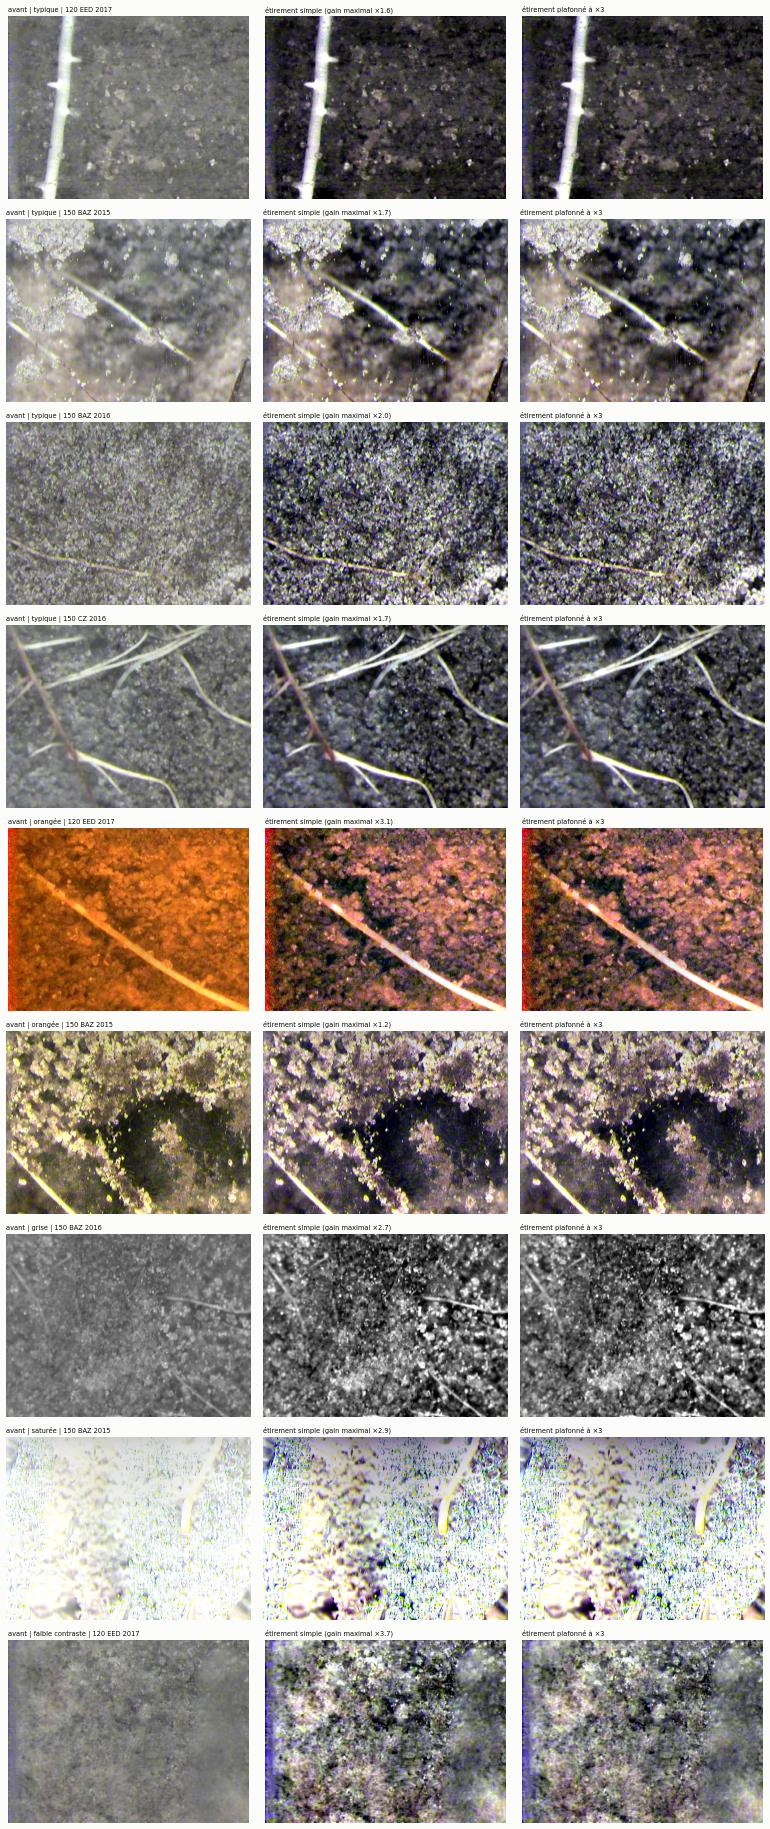

In [4]:
# Un exemple par situation (premier trouvé dans l'échantillon val)
wanted = [('typique', '120 EED 2017'), ('typique', '150 BAZ 2015'), ('typique', '150 BAZ 2016'), ('typique', '150 CZ 2016'),
          ('orangée', '120 EED 2017'), ('orangée', '150 BAZ 2015'), ('grise', '150 BAZ 2016'),
          ('saturée', '150 BAZ 2015'), ('faible contraste', '120 EED 2017')]
rows = [val_s[(val_s['cas'] == c) & (val_s['group'] == g)].iloc[0] for c, g in wanted
        if ((val_s['cas'] == c) & (val_s['group'] == g)).any()]
fig, axes = plt.subplots(len(rows), 3, figsize=(13, 3.4 * len(rows)))
for ax_row, r in zip(axes, rows):
    fond, _ = load(r)
    simple, span = normalize(fond, None)
    capped, _ = normalize(fond, 3)
    for ax, im, title in zip(ax_row, [fond, simple, capped],
                             [f"avant | {r['cas']} | {r['group']}", f'étirement simple (gain maximal ×{1 / span.min():.1f})', 'étirement plafonné à ×3']):
        ax.imshow(im)
        ax.set_title(title, loc='left', fontsize=8)
        ax.axis('off')
fig.tight_layout()
viz.save(fig, '02_norm_avant_apres.jpg')

- Plafond à ×3 : presque aucune différence visible avec l'étirement simple. Il ne joue que sur les images dont le gain dépasse 3 (le faible contraste ci-dessus passe de ×3,7 à ×3).
- Le bruit de l'image à faible contraste reste gonflé. Son masque (4 222 pixels) désigne une racine qu'on ne distingue pas à l'œil : annotation douteuse.

## 4. Mesures

Trois versions comparées : avant (fond corrigé), étirement simple, étirement plafonné à ×3.

In [5]:
VERSIONS = ['avant', 'simple', 'plafonné']


def measure(row, n_px=2000):
    fond, mask = load(row)
    versions = {'avant': fond, 'simple': normalize(fond, None)[0], 'plafonné': normalize(fond, 3)[0]}
    rng = np.random.default_rng(0)
    root = np.flatnonzero(ndi.binary_erosion(mask))                  # coeur de la racine
    soil = np.flatnonzero(~ndi.binary_dilation(mask, iterations=5))  # sol loin du masque
    root, soil = rng.choice(root, min(n_px, len(root)), replace=False), rng.choice(soil, n_px, replace=False)
    out = {'group': row['group'], 'cas': row['cas'], 'gain': 1 / normalize(fond, None)[1]}
    for key, im in versions.items():
        px = im.reshape(-1, 3)
        out[key] = {'mean': px.mean(0) * 255, 'root': px[root], 'soil': px[soil]}
    return out


meas_val = [measure(r) for _, r in val_s.iterrows()]
meas_train = [measure(r) for _, r in train_s.iterrows()]
len(meas_val), len(meas_train)

(160, 160)

### 4.1 Homogénéité entre images

Dispersion (écart-type entre images) de la luminosité moyenne et du rapport R/B.

In [6]:
def per_image(meas, key):
    m = np.array([x[key]['mean'] for x in meas])
    return pd.DataFrame({'group': [x['group'] for x in meas], 'luminosité': m @ [0.299, 0.587, 0.114], 'R/B': m[:, 0] / m[:, 2]})


def spread(f):
    s = f.groupby('group')[['luminosité', 'R/B']].std().loc[G]
    s.loc['tous groupes'] = f[['luminosité', 'R/B']].std()
    return s


pd.concat({k: spread(per_image(meas_val, k)) for k in VERSIONS}, axis=1).round(2)

avant           simple         plafonné      
             luminosité   R/B luminosité   R/B luminosité   R/B
group                                                          
150 BAZ 2015      30.32  0.35      27.18  0.09      27.18  0.09
150 BAZ 2016      27.15  0.03      15.82  0.07      15.82  0.07
150 CZ 2016        7.85  0.02      11.10  0.04      11.12  0.04
120 EED 2017       7.12  1.25      17.32  0.15      17.37  0.15
tous groupes      22.49  0.65      20.05  0.10      20.06  0.09

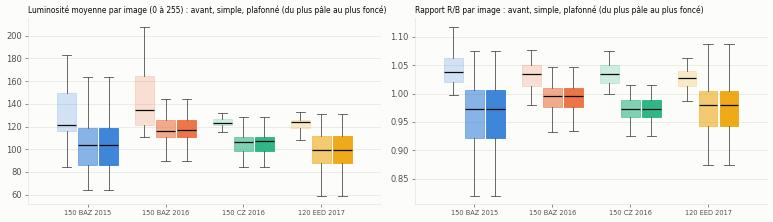

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
frames = {k: per_image(meas_val, k) for k in VERSIONS}
alphas = {'avant': 0.2, 'simple': 0.55, 'plafonné': 0.9}
for ax, col, title in zip(axes, ['luminosité', 'R/B'], ['Luminosité moyenne par image (0 à 255)', 'Rapport R/B par image']):
    for i, g in enumerate(G):
        for off, k in zip((-0.27, 0, 0.27), VERSIONS):
            f = frames[k]
            ax.boxplot(f.loc[f['group'] == g, col], positions=[i + off], widths=0.24, showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor=viz.GROUP_COLORS[g], edgecolor=viz.GROUP_COLORS[g], alpha=alphas[k]),
                       medianprops=dict(color=viz.INK, linewidth=1.5), whiskerprops=dict(color=viz.INK_2), capprops=dict(color=viz.INK_2))
    ax.set_xticks(range(len(G)), G, fontsize=8)
    ax.set_title(title + ' : avant, simple, plafonné (du plus pâle au plus foncé)', loc='left', fontsize=9)
    ax.grid(axis='x', visible=False)
fig.tight_layout()
viz.save(fig, '02_homogeneite.png')

- R/B : dispersion entre images divisée par 6 (0,65 → 0,10 tous groupes ; 120 DPI : 1,25 → 0,15). Le gain vient des sessions orangées.
- Luminosité : pas d'homogénéisation systématique. Mieux en BAZ 2016 (27 → 16), à peine en BAZ 2015 (30 → 27) ; pire en 120 DPI (7 → 17) et CZ 2016 (8 → 11), déjà stables avant.
- Simple et plafonné : mêmes dispersions.

### 4.2 Séparation racine / sol avec un mélange de couleurs fixe

Un seul mélange `a R + b G + c B` par version, appris sur l'échantillon du train, appliqué à l'échantillon du val. Score d' comme dans le notebook 01, signé : négatif si la racine est plus sombre dans le mélange.

In [8]:
def fit_mix(meas, key):
    root = np.concatenate([x[key]['root'] for x in meas])
    soil = np.concatenate([x[key]['soil'] for x in meas])
    w = np.linalg.solve((np.cov(root.T) + np.cov(soil.T)) / 2, root.mean(0) - soil.mean(0))
    return w / np.abs(w).sum()


def dprime(x, key, w):
    a, b = x[key]['root'] @ w, x[key]['soil'] @ w
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


w = {k: fit_mix(meas_train, k) for k in VERSIONS}
print({k: v.round(2) for k, v in w.items()})
sep = pd.DataFrame({'group': [x['group'] for x in meas_val], 'cas': [x['cas'] for x in meas_val],
                    **{k: [dprime(x, k, w[k]) for x in meas_val] for k in VERSIONS}})
sep['écart'] = sep['plafonné'] - sep['avant']


def summarize(by, order):
    s = sep.groupby(by)
    return pd.DataFrame({'n': s.size(), **{k: s[k].median() for k in VERSIONS},
                         'écart médian (plafonné - avant)': s['écart'].median(),
                         'images améliorées, %': s['écart'].apply(lambda x: 100 * (x > 0).mean())}).loc[order]


pd.concat({'par groupe': summarize('group', G), 'par type': summarize('cas', ['typique'] + HARD)}).round(2)

{'avant': array([ 0.47,  0.3 , -0.23]), 'simple': array([ 0.63, -0.24, -0.13]), 'plafonné': array([ 0.63, -0.24, -0.13])}


n  avant  simple  plafonné  écart médian (plafonné - avant)  images améliorées, %
par groupe 150 BAZ 2015       40   1.64    1.77      1.77                             0.03                 62.50
           150 BAZ 2016       40   1.47    1.50      1.49                             0.20                 80.00
           150 CZ 2016        40   1.77    1.83      1.83                             0.16                 87.50
           120 EED 2017       40   2.09    2.17      2.17                             0.12                 65.00
par type   typique           104   1.75    1.92      1.92                             0.14                 76.92
           orangée             8   1.07    1.22      1.21                            -0.02                 37.50
           grise               8   1.47    1.74      1.70                             0.03                 62.50
           saturée             8   1.62    1.43      1.44                            -0.07                 50.00
           faible contraste   16   1.93    2.03      2.03                             0.26                 87.50
           sombre             16   2.06    2.10      2.10                             0.20                 75.00

- d' médian en hausse dans les 4 groupes (écart médian de +0,03 à +0,20 ; 63 à 88 % des images améliorées).
- Images typiques : 1,75 → 1,92, 77 % améliorées : pas de dégradation.
- Pas de gain net pour les images orangées (38 % améliorées) ni saturées (1,62 → 1,44).
- Simple et plafonné : écart d'au plus 0,04.
- Cas difficiles : 8 à 16 images, tendances seulement.

### 4.3 Effets secondaires : amplification

Gain de l'étirement simple, canal le plus étiré de l'image. Au-dessus de 3, le plafond intervient.

In [9]:
gain = pd.DataFrame({'group': [x['group'] for x in meas_val], 'cas': [x['cas'] for x in meas_val],
                     'gain': [x['gain'].max() for x in meas_val]})
pd.concat({
    'par groupe': gain.groupby('group')['gain'].agg(médiane='median', maximum='max', part_sup_3=lambda s: 100 * (s > 3).mean()).loc[G],
    'par type': gain.groupby('cas')['gain'].agg(médiane='median', maximum='max', part_sup_3=lambda s: 100 * (s > 3).mean()).loc[['typique'] + HARD],
}).round(1)

médiane  maximum  part_sup_3
par groupe 150 BAZ 2015          1.6      2.9         0.0
           150 BAZ 2016          2.0      3.7         5.0
           150 CZ 2016           2.2      3.4         7.5
           120 EED 2017          2.3      3.7        15.0
par type   typique               1.9      3.0         0.0
           orangée               2.8      3.3        25.0
           grise                 2.5      3.4        12.5
           saturée               1.8      2.9         0.0
           faible contraste      3.0      3.7        50.0
           sombre                2.1      2.9         0.0

- Gain maximal médian de 1,6 à 2,3 selon le groupe, au plus 3,7. Images typiques : aucune au-dessus de 3.
- Au-dessus de 3 : 50 % des images à faible contraste, 25 % des orangées, 12 % des grises, 15 % du 120 DPI.
- Le plafond à ×3 retranche au plus 0,7 de gain : effet marginal. Un plafond plus bas toucherait aussi des images typiques.

## 5. Synthèse

Normalisation par centiles, plafonnée à ×3 par sécurité :
- corrige la dominante de couleur (sessions orangées) ;
- améliore un peu la séparation racine / sol pour un mélange fixe, sans dégrader les images typiques.

Limites :
- n'homogénéise pas la luminosité, la dégrade même pour les groupes déjà stables (120 DPI, CZ 2016) ;
- le plafond à ×3 ne règle pas le bruit des images peu contrastées (effet quasi nul) ;
- fragilise les images saturées, accentue le liseré coloré du bord gauche du 120 DPI ;
- vérifié sur 160 images du val, dont 56 cas difficiles (8 à 16 par type).

**Décision** : on garde cette normalisation. Les cas extrêmes sont couverts par les augmentations à l'entraînement (notebook E2 : gamma, surexposition, bruit, flou ; pas de dominante orange, que la normalisation annule déjà). Variantes non testées : correction de couleur seule, étirement fondé sur la médiane et l'écart interquartile.

Chaîne retenue : `preprocess_image` dans `src/prmi/preprocess.py` (recadrage du 120 DPI, correction du fond, normalisation). Cartes de fond enregistrées dans `data/processed/flatfields.npz`.

## 6. La chaîne complète en images

Les images gardent leur position d'origine dans le cadre : les marges vides du 120 DPI sont les bandes retirées par le recadrage.

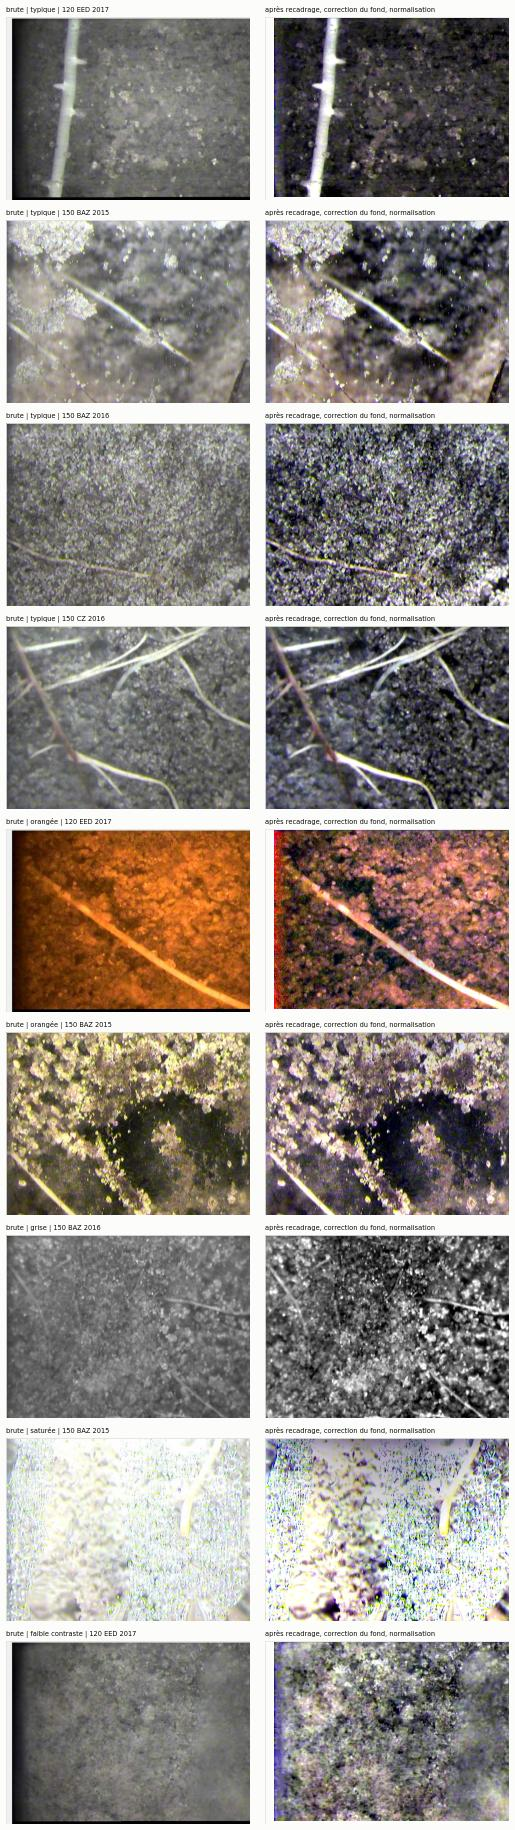

In [10]:
# Image brute (non recadrée) et image après toute la chaîne : recadrage, fond, normalisation plafonnée
def show(ax, img, offset=(0, 0), full=(480, 640)):
    h, w = img.shape[:2]
    ax.imshow(img, extent=(offset[1], offset[1] + w, offset[0] + h, offset[0]))
    ax.add_patch(plt.Rectangle((0, 0), full[1], full[0], fill=False, ec=viz.GRID, lw=1))
    ax.set_xlim(0, full[1])
    ax.set_ylim(full[0], 0)
    ax.axis('off')


def chain(row):
    raw = np.asarray(Image.open(RAW / row['image_path']).convert('RGB'))
    crop = crop_for(int(row['dpi']))
    fond = preprocess(raw, flats[row['group']], crop).astype(np.float32) / 255
    return raw, crop, fond, normalize(fond)[0]


fig, axes = plt.subplots(len(rows), 2, figsize=(9, 3.4 * len(rows)))
for ax_row, r in zip(axes, rows):
    raw, crop, _, final = chain(r)
    show(ax_row[0], raw, full=raw.shape[:2])
    show(ax_row[1], final, offset=(crop[0].start or 0, crop[1].start or 0), full=raw.shape[:2])
    ax_row[0].set_title(f"brute | {r['cas']} | {r['group']}", loc='left', fontsize=8)
    ax_row[1].set_title('après recadrage, correction du fond, normalisation', loc='left', fontsize=8)
fig.tight_layout()
viz.save(fig, '02_chaine_complete.jpg')

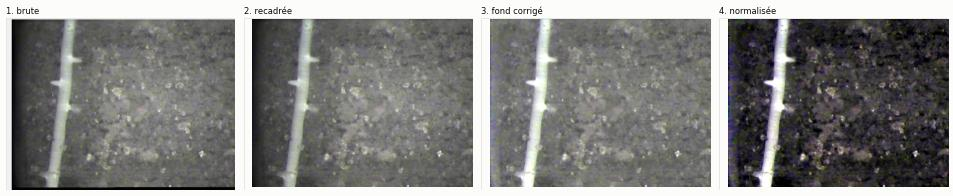

In [11]:
# Les étapes successives sur une image typique du 120 DPI
r = val_s[(val_s['cas'] == 'typique') & (val_s['group'] == '120 EED 2017')].iloc[0]
raw, crop, fond, final = chain(r)
off = (crop[0].start or 0, crop[1].start or 0)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, img, offset, title in zip(axes, [raw, raw[crop], fond, final], [(0, 0), off, off, off],
                                  ['1. brute', '2. recadrée', '3. fond corrigé', '4. normalisée']):
    show(ax, img, offset)
    ax.set_title(title, loc='left', fontsize=10)
fig.tight_layout()
viz.save(fig, '02_chaine_etapes.jpg')